<a href="https://colab.research.google.com/github/emrizky1/machine-learning/blob/main/JS09/JS09_Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install annoy faiss-cpu hnswlib kagglehub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 16.0 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 33.7 MB/s  0:00:00
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520955 sha256=1897f5d2d04bf67ddf185316606556255dbf1b753ce34f61b5147d2c88ef03e7
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679070 sha256=debab58e3c7c8d47a0ecd6b52f900f8200cd1296eafafcc0a633faa9829951c0
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f5

In [2]:
import glob, time
import numpy as np
import pandas as pd
import faiss
import hnswlib
import matplotlib.pyplot as plt
from annoy import AnnoyIndex
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
k = 10
N_QUERIES = 1000

In [3]:
import kagglehub
path = kagglehub.dataset_download("bwandowando/spotify-songs-with-attributes-and-lyrics")
csv_files = sorted(glob.glob(f"{path}/**/*.csv", recursive=True))
print(csv_files)
df = pd.read_csv(csv_files[0])

print(df.shape)
df.head()

Using Colab cache for faster access to the 'spotify-songs-with-attributes-and-lyrics' dataset.
['/kaggle/input/spotify-songs-with-attributes-and-lyrics/songs_with_attributes_and_lyrics.csv', '/kaggle/input/spotify-songs-with-attributes-and-lyrics/songs_with_lyrics_and_timestamps.csv']
(955320, 17)


,id,name,album_name,artists,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,lyrics
0,0Prct5TDjAnEgIqbxcldY9,!,UNDEN!ABLE,HELLYEAH,0.415,0.6050,7,-11.157,1,0.0575,0.00116,0.838000,0.4710,0.193,100.059,79500.0,"He said he came from Jamaica,\n he owned a cou..."
1,2ASl4wirkeYm3OWZxXKYuq,!!,NaN,Yxngxr1,0.788,0.6480,7,-9.135,0,0.3150,0.90000,0.000000,0.1760,0.287,79.998,114000.0,"Fucked a bitch, now she running with my kids\n..."
2,69lcggVPmOr9cvPx9kLiiN,!!! - Interlude,Where I Belong EP,Glowie,0.000,0.0354,7,-20.151,0,0.0000,0.90800,0.000000,0.4790,0.000,0.000,11413.0,"Oh, my God, I'm going crazy\n"
3,4U7dlZjg1s9pjdppqZy0fm,!!De Repente!!,Un Palo Al Agua (20 Grandes Canciones),Rosendo,0.657,0.8820,5,-6.340,1,0.0385,0.00740,0.000013,0.0474,0.939,123.588,198173.0,Continuamente se extraña la gente si no puede ...
4,4v1IBp3Y3rpkWmWzIlkYju,!!De Repente!!,Fuera De Lugar,Rosendo,0.659,0.8930,5,-8.531,1,0.0411,0.09220,0.000019,0.0534,0.951,123.600,199827.0,Continuamente se extraña la gente si no puede ...


In [4]:
boilerplate = ['danceability', 'energy', 'loudness', 'speechiness',
               'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

features = [c for c in boilerplate if c in df.columns]
if len(features) < len(boilerplate):
    drop_like = ['unnamed', 'id', 'year', 'index']
    features = [c for c in df.select_dtypes(include=np.number).columns
                if not any(d in c.lower() for d in drop_like)]
print("Features used:", features)

df = df.dropna(subset=features).reset_index(drop=True)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features].values).astype("float32")
print("Scaled data:", X_scaled.shape)

perm = np.random.permutation(len(X_scaled))
q_ids, db_ids = perm[:N_QUERIES], perm[N_QUERIES:]
X = np.ascontiguousarray(X_scaled[db_ids])
Q = np.ascontiguousarray(X_scaled[q_ids])
meta = df.iloc[db_ids].reset_index(drop=True)
q_meta = df.iloc[q_ids].reset_index(drop=True)
n, d = X.shape
print(f"Database: {n:,} tracks, {d} dimensions | Queries: {len(Q)}")

Features used: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
Scaled data: (955320, 9)
Database: 954,320 tracks, 9 dimensions | Queries: 1000


In [5]:
t0 = time.perf_counter()
nn = NearestNeighbors(n_neighbors=k, algorithm="brute", metric="euclidean", n_jobs=-1)
nn.fit(X)
build_exact = time.perf_counter() - t0

t0 = time.perf_counter()
_, I_exact = nn.kneighbors(Q)
total_exact = time.perf_counter() - t0
print(f"Exact NN  build={build_exact:.3f}s  query total={total_exact:.3f}s  "
      f"({total_exact/len(Q)*1000:.4f} ms/query)")

Exact NN  build=0.020s  query total=5.307s  (5.3068 ms/query)


In [6]:
N_TREES = 20

t0 = time.perf_counter()
annoy_idx = AnnoyIndex(d, "euclidean")
for i, v in enumerate(X):
    annoy_idx.add_item(i, v)
annoy_idx.build(N_TREES)
build_annoy = time.perf_counter() - t0

t0 = time.perf_counter()
I_annoy = np.array([annoy_idx.get_nns_by_vector(q, k) for q in Q])
total_annoy = time.perf_counter() - t0
print(f"ANNOY  build={build_annoy:.3f}s  query total={total_annoy:.3f}s")

ANNOY  build=26.316s  query total=0.116s


In [7]:
nlist = int(np.sqrt(n))
m = d
nprobe = 10

quantizer = faiss.IndexFlatL2(d)
faiss_idx = faiss.IndexIVFPQ(quantizer, d, nlist, m, 8)

t0 = time.perf_counter()
train_ids = np.random.choice(n, min(n, 200_000), replace=False)
faiss_idx.train(X[train_ids])
faiss_idx.add(X)
build_faiss = time.perf_counter() - t0

faiss_idx.nprobe = nprobe
t0 = time.perf_counter()
_, I_faiss = faiss_idx.search(Q, k)
total_faiss = time.perf_counter() - t0
print(f"FAISS  build={build_faiss:.3f}s  query total={total_faiss:.3f}s")

FAISS  build=30.996s  query total=0.136s


In [8]:
t0 = time.perf_counter()
hnsw_idx = hnswlib.Index(space="l2", dim=d)
hnsw_idx.init_index(max_elements=n, ef_construction=200, M=16)
hnsw_idx.add_items(X, np.arange(n))
build_hnsw = time.perf_counter() - t0

hnsw_idx.set_ef(50)
t0 = time.perf_counter()
I_hnsw, _ = hnsw_idx.knn_query(Q, k=k)
total_hnsw = time.perf_counter() - t0
print(f"HNSW  build={build_hnsw:.3f}s  query total={total_hnsw:.3f}s")

HNSW  build=160.256s  query total=0.048s


In [9]:
def recall_at_k(I_approx, I_true):
    return np.mean([len(set(a) & set(t)) / len(t) for a, t in zip(I_approx, I_true)])

rows = [
    ("Exact NN", build_exact, total_exact, I_exact),
    ("ANNOY",    build_annoy, total_annoy, I_annoy),
    ("FAISS",    build_faiss, total_faiss, I_faiss),
    ("HNSW",     build_hnsw,  total_hnsw,  I_hnsw),
]

summary = pd.DataFrame([{
    "Method": name,
    "Build time (s)": round(b, 3),
    "Total query time (s)": round(t, 4),
    "Avg query time (ms)": round(t / len(Q) * 1000, 4),
    f"Recall@{k}": round(recall_at_k(I, I_exact), 4),
    "Speedup vs Exact": round(total_exact / t, 2),
} for name, b, t, I in rows])

display(summary)

,Method,Build time (s),Total query time (s),Avg query time (ms),Recall@10,Speedup vs Exact
0,Exact NN,0.020,5.3068,5.3068,1.0000,1.00
1,ANNOY,26.316,0.1160,0.1160,0.9306,45.75
2,FAISS,30.996,0.1364,0.1364,0.9650,38.91
3,HNSW,160.256,0.0482,0.0482,0.9952,110.20


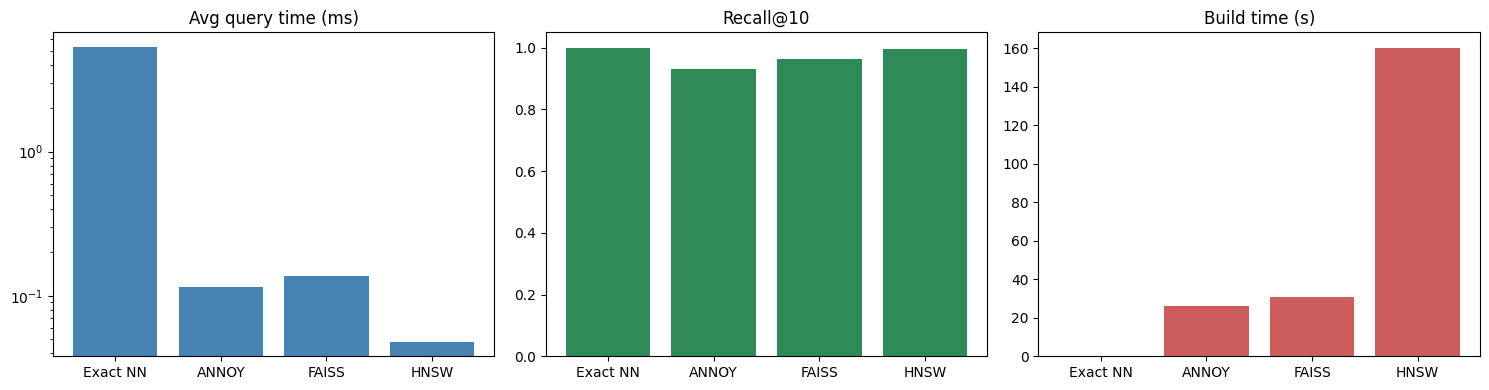

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].bar(summary["Method"], summary["Avg query time (ms)"], color="steelblue")
ax[0].set_title("Avg query time (ms)"); ax[0].set_yscale("log")
ax[1].bar(summary["Method"], summary[f"Recall@{k}"], color="seagreen")
ax[1].set_title(f"Recall@{k}"); ax[1].set_ylim(0, 1.05)
ax[2].bar(summary["Method"], summary["Build time (s)"], color="indianred")
ax[2].set_title("Build time (s)")
plt.tight_layout(); plt.show()

In [11]:
name_col = next((c for c in ["name", "track_name", "song", "title"] if c in df.columns), None)
artist_col = next((c for c in ["artists", "artist", "artist_name"] if c in df.columns), None)
show_cols = [c for c in [name_col, artist_col] if c]

qi = 0
print("QUERY TRACK:")
display(q_meta.loc[[qi], show_cols])

for name, _, _, I in rows:
    print(f"\nTop-5 nearest tracks: {name}")
    display(meta.iloc[I[qi][:5]][show_cols].reset_index(drop=True))

QUERY TRACK:


,name,artists
0,Dans La Nuit,Sarah Brightman



Top-5 nearest tracks: Exact NN


,name,artists
0,Blue (with Sarah Vaughan),"Barry Manilow, Sarah Vaughan"
1,Revolutions,Nobuo Uematsu
2,Blue (with Sarah Vaughan),"Barry Manilow, Sarah Vaughan"
3,We Have All The Time In The World,Alfie Boe
4,"Vesti la giubba (From ""For the First Time"")",Mario Lanza



Top-5 nearest tracks: ANNOY


,name,artists
0,Blue (with Sarah Vaughan),"Barry Manilow, Sarah Vaughan"
1,Revolutions,Nobuo Uematsu
2,Blue (with Sarah Vaughan),"Barry Manilow, Sarah Vaughan"
3,We Have All The Time In The World,Alfie Boe
4,"Vesti la giubba (From ""For the First Time"")",Mario Lanza



Top-5 nearest tracks: FAISS


,name,artists
0,Blue (with Sarah Vaughan),"Barry Manilow, Sarah Vaughan"
1,Revolutions,Nobuo Uematsu
2,Blue (with Sarah Vaughan),"Barry Manilow, Sarah Vaughan"
3,We Have All The Time In The World,Alfie Boe
4,"Vesti la giubba (From ""For the First Time"")",Mario Lanza



Top-5 nearest tracks: HNSW


,name,artists
0,Blue (with Sarah Vaughan),"Barry Manilow, Sarah Vaughan"
1,Revolutions,Nobuo Uematsu
2,Blue (with Sarah Vaughan),"Barry Manilow, Sarah Vaughan"
3,We Have All The Time In The World,Alfie Boe
4,"Vesti la giubba (From ""For the First Time"")",Mario Lanza
